# Classification d'articles de presse — AG News

**Objectif :** prédire automatiquement le domaine d'un article de presse parmi 4 catégories : *Monde*, *Sport*, *Business* et *Science/Technologie*.

**Données :** AG News (version Hugging Face `fancyzhx/ag_news`), 127 600 articles au total (120 000 en train, 7 600 en test). Chaque observation correspond au titre suivi du début de l'article.

Plan du notebook :

1. Chargement et exploration des données
2. Nettoyage du texte et découpage train / validation / test
3. Modèles de machine learning classiques (TF-IDF + Naive Bayes, régression logistique, SVM linéaire)
4. Modèles de deep learning (moyenne d'embeddings type fastText, CNN 1D, BiLSTM)
5. Comparaison des modèles et choix du modèle final
6. Analyse des erreurs du modèle retenu, calibration des probabilités et sauvegarde pour la webapp

In [1]:
import re
import html
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, log_loss)

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

LABELS = ["Monde", "Sport", "Business", "Sci/Tech"]
print("torch", torch.__version__, "| GPU dispo :", torch.cuda.is_available())

torch 2.2.2 | GPU dispo : False


## 1. Chargement des données

Le dataset est récupéré depuis Hugging Face, puis enregistré en local dans `data/train.csv` et `data/test.csv` (colonnes `text` et `label`) pour ne pas le retélécharger à chaque exécution.

Correspondance des labels (d'après la fiche du dataset) : 0 = World, 1 = Sports, 2 = Business, 3 = Sci/Tech.

In [2]:
DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)

def load_split(split):
    path = DATA_DIR / f"{split}.csv"
    if not path.exists():
        # première exécution : téléchargement depuis Hugging Face puis export en csv
        from huggingface_hub import hf_hub_download
        f = hf_hub_download("fancyzhx/ag_news", f"data/{split}-00000-of-00001.parquet",
                            repo_type="dataset")
        pd.read_parquet(f).to_csv(path, index=False)
    return pd.read_csv(path, keep_default_na=False)

train_df = load_split("train")
test_df = load_split("test")

print("train :", train_df.shape, "| test :", test_df.shape,
      "| total :", len(train_df) + len(test_df))
train_df.head()

train : (120000, 2) | test : (7600, 2) | total : 127600


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


## 2. Exploration du jeu de données

### 2.1 Qualité des données
On vérifie d'abord les valeurs manquantes et les doublons, puis la répartition des classes.

In [3]:
print("Valeurs manquantes (train) :\n", train_df.isna().sum(), sep="")
print("\nDoublons dans le train :", train_df.duplicated("text").sum())
print("Doublons dans le test  :", test_df.duplicated("text").sum())

# articles présents à la fois dans le train et dans le test -> risque de fuite
commun = set(train_df.text) & set(test_df.text)
print("Textes communs train/test :", len(commun))

# même texte mais labels différents ?
conflits = train_df.groupby("text").label.nunique()
print("Textes avec plusieurs labels :", (conflits > 1).sum())

Valeurs manquantes (train) :
text     0
label    0
dtype: int64



Doublons dans le train : 0
Doublons dans le test  : 0


Textes communs train/test : 0
Textes avec plusieurs labels : 0


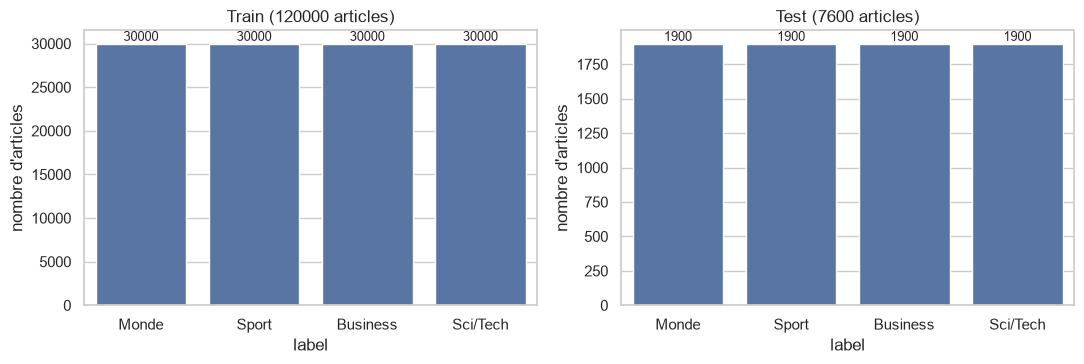

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (nom, df) in zip(axes, [("Train", train_df), ("Test", test_df)]):
    cnt = df.label.map(dict(enumerate(LABELS))).value_counts().reindex(LABELS)
    sns.barplot(x=cnt.index, y=cnt.values, ax=ax, color="#4C72B0")
    ax.set_title(f"{nom} ({len(df)} articles)")
    ax.set_ylabel("nombre d'articles")
    for i, v in enumerate(cnt.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Les classes sont **parfaitement équilibrées** (30 000 articles par classe en train, 1 900 en test). C'est plutôt confortable :

- pas besoin de rééchantillonnage ni de pondération des classes ;
- l'accuracy est une métrique pertinente (une prédiction au hasard donne 25 %). Je regarde quand même le F1 macro en complément.

Il y a quelques doublons et des textes communs entre train et test, mais en quantité négligeable par rapport à la taille du jeu. Je supprime les doublons du train pour ne pas sur-pondérer certains articles, mais je ne touche pas au test, qui reste le jeu de test officiel et permet de comparer avec d'autres travaux.

In [5]:
avant = len(train_df)
train_df = train_df.drop_duplicates("text").reset_index(drop=True)
print(f"{avant - len(train_df)} doublons supprimés -> {len(train_df)} articles en train")

0 doublons supprimés -> 120000 articles en train


### 2.2 Quelques exemples par classe

In [6]:
pd.set_option("display.max_colwidth", 200)
for k, nom in enumerate(LABELS):
    print(f"--- {nom} ---")
    for t in train_df[train_df.label == k].text.sample(2, random_state=1):
        print(" *", t[:200])
    print()

--- Monde ---
 * Haitians Pray for 1,500 Killed by Jeanne (AP) AP - In a cathedral ankle-deep in mud and overturned pews, Haitians prayed for 1,500 killed by Tropical Storm Jeanne and gave thanks for their lives  #151
 * U.S.-Led Forces Tighten Grip, Draw Complaints  SAMARRA, Iraq (Reuters) - U.S.-led forces tightened their  grip on a rebel-held city on Sunday in the first step of a  campaign to take back all of Iraq 

--- Sport ---
 * Arsenal, Facing Rosenborg in Europe, Loses Gilberto (Update1) Arsenal midfielder Gilberto Silva will miss the team #39;s second Champions League group game against Norwegian champion Rosenborg on Wedn
 * Storm game at a glance PLAYER OF THE GAME: Playing with a broken nose, Seattle point guard Sue Bird set a WNBA playoff record for assists with 14, also pumping in 10 points as the Storm claimed the We

--- Business ---
 * US Jobless Claims Up, Consumption Flat (Reuters) Reuters - U.S. claims for jobless benefits\jumped last week, while consumer spending 

En lisant les exemples, on remarque plusieurs choses à prendre en compte pour le nettoyage :

- des retours à la ligne codés en `\` (ex. `Wall Street's dwindling\band of...`) ;
- des entités HTML mal décodées comme `#39;` (apostrophe), `&lt;`, `quot;` ;
- le nom de l'agence de presse en tête d'article (`(Reuters)`, `AFP -`, `(AP)`...). Ça peut être un indice pour le modèle (Reuters écrit beaucoup sur la finance par exemple), mais ça ne dit rien du contenu. Je le laisse pour l'instant et je regarderai son influence plus bas.

### 2.3 Longueur des textes
La longueur est importante pour les modèles de deep learning, qui ont besoin d'une taille de séquence fixe.

count    120000.0
mean         37.8
std          10.1
min           8.0
25%          32.0
50%          37.0
75%          43.0
max         177.0
Name: n_mots, dtype: float64


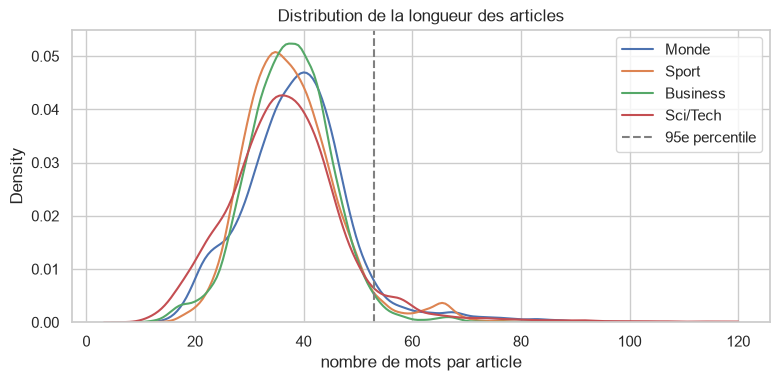

In [7]:
train_df["n_mots"] = train_df.text.str.split().str.len()
print(train_df.n_mots.describe().round(1))

plt.figure(figsize=(9, 3.8))
for k, nom in enumerate(LABELS):
    sns.kdeplot(train_df[train_df.label == k].n_mots, label=nom, clip=(0, 120))
plt.axvline(train_df.n_mots.quantile(0.95), color="grey", ls="--", label="95e percentile")
plt.xlabel("nombre de mots par article")
plt.legend()
plt.title("Distribution de la longueur des articles")
plt.show()

Les textes sont **courts** : environ 38 mots en moyenne, et 95 % des articles font moins de ~55 mots. La distribution est à peu près la même pour les 4 classes, donc la longueur seule ne permet pas de les distinguer.

Conséquence pratique : pour les réseaux de neurones, une longueur maximale d'environ 60 tokens suffit et ne coupe presque aucun article.

### 2.4 Vocabulaire caractéristique de chaque classe
On compte les mots les plus fréquents par classe en enlevant les mots vides (*stop words*) anglais.

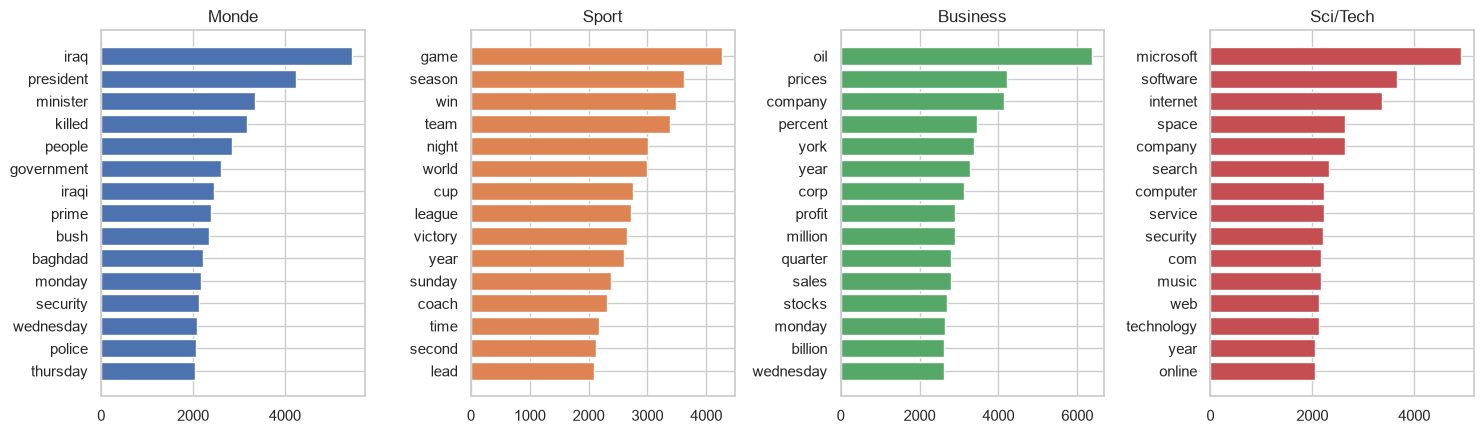

In [8]:
def nettoyer(texte):
    # nettoyage minimal, gardé volontairement simple
    t = texte.replace("\\", " ")
    t = html.unescape(t)
    t = re.sub(r"#\d+;", "'", t)              # entités du type #39; restées dans le texte
    t = re.sub(r"&?(quot|lt|gt|amp);", " ", t)
    t = re.sub(r"<[^>]+>", " ", t)            # restes de balises
    t = re.sub(r"\s+", " ", t)
    return t.strip().lower()

def tokens(texte):
    return re.findall(r"[a-z0-9']+", texte)

stop = set(ENGLISH_STOP_WORDS) | {"s", "said", "new", "reuters", "ap", "afp", "quot", "39", "lt", "gt"}

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for k, ax in enumerate(axes):
    c = Counter(w for t in train_df[train_df.label == k].text.map(nettoyer)
                for w in tokens(t) if w not in stop and len(w) > 2)
    mots, freq = zip(*c.most_common(15))
    ax.barh(mots[::-1], freq[::-1], color=sns.color_palette()[k])
    ax.set_title(LABELS[k])
plt.tight_layout()
plt.show()

Les mots fréquents sont très parlants : *iraq, president, killed* pour Monde, *game, season, team* pour Sport, *oil, prices, company* pour Business, *microsoft, software, internet* pour Sci/Tech. Le vocabulaire est donc très discriminant, ce qui laisse penser qu'une simple représentation en sac de mots (TF-IDF) peut déjà bien marcher.

On voit aussi d'où viendront les confusions : Business et Sci/Tech partagent beaucoup de vocabulaire d'entreprise (*company, inc, deal*), et Monde et Business ont en commun les sujets économiques (*oil*, gouvernements...).

## 3. Préparation des données

- **Nettoyage :** la fonction `nettoyer` définie au-dessus (correction des artefacts + minuscules). Je ne fais **ni lemmatisation ni suppression des stop words** pour les modèles : avec TF-IDF et des bigrammes, des expressions comme *"world cup"* ou *"wall street"* sont utiles, et les modèles linéaires gèrent bien les mots peu informatifs grâce à la pondération IDF.
- **Découpage :** je sépare 10 % du train en **validation** (stratifiée). Tous les choix d'hyperparamètres se font sur la validation ; le **test n'est utilisé qu'une seule fois à la fin** pour évaluer les modèles, sinon on surestimerait les performances.

In [9]:
train_df["clean"] = train_df.text.map(nettoyer)
test_df["clean"] = test_df.text.map(nettoyer)

tr_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df.label,
                                 random_state=SEED)
X_tr, y_tr = tr_df.clean.values, tr_df.label.values
X_val, y_val = val_df.clean.values, val_df.label.values
X_test, y_test = test_df.clean.values, test_df.label.values
print(f"train : {len(X_tr)} | validation : {len(X_val)} | test : {len(X_test)}")

print("\navant :", train_df.text.iloc[0][:150])
print("après :", train_df.clean.iloc[0][:150])

train : 108000 | validation : 12000 | test : 7600

avant : Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
après : wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling band of ultra-cynics, are seeing green again.


In [10]:
# tableau où je stocke les résultats de chaque modèle pour la comparaison finale
resultats = []

def evaluer(nom, famille, y_pred, t_train, t_pred, extra=None):
    r = {"modèle": nom, "famille": famille,
         "accuracy": accuracy_score(y_test, y_pred),
         "f1_macro": f1_score(y_test, y_pred, average="macro"),
         "temps_entrainement_s": round(t_train, 1),
         "temps_prediction_test_s": round(t_pred, 2)}
    if extra:
        r.update(extra)
    resultats.append(r)
    print(f"{nom:35s} accuracy test = {r['accuracy']:.4f} | F1 macro = {r['f1_macro']:.4f}")

### Baseline
Avant de construire des modèles, une baseline triviale donne un point de comparaison. Prédire toujours la même classe donne 25 % d'accuracy, puisque les classes sont équilibrées.

In [11]:
evaluer("Baseline (classe majoritaire)", "baseline", np.zeros_like(y_test), 0, 0)

Baseline (classe majoritaire)       accuracy test = 0.2500 | F1 macro = 0.1000


## 4. Machine learning classique : TF-IDF + modèles linéaires

**Représentation TF-IDF :** chaque article devient un vecteur creux où chaque dimension correspond à un mot (ou un bigramme), pondéré par sa fréquence dans l'article et par sa rareté dans le corpus. Mes choix :

- `ngram_range=(1, 2)` : les bigrammes capturent des expressions (*"prime minister"*, *"stock market"*) ;
- `min_df=2` : on ignore les termes vus une seule fois (souvent des fautes ou des noms très rares) ;
- `sublinear_tf=True` : on remplace tf par 1 + log(tf) pour qu'un mot répété ne pèse pas trop ;
- `max_features=300 000` pour limiter la taille du modèle.

Je compare d'abord rapidement unigrammes et uni+bigrammes sur la validation pour vérifier que les bigrammes apportent quelque chose.

In [12]:
for ngr in [(1, 1), (1, 2)]:
    v = TfidfVectorizer(ngram_range=ngr, min_df=2, sublinear_tf=True, max_features=300_000)
    A = v.fit_transform(X_tr)
    clf = LinearSVC(C=0.5).fit(A, y_tr)
    print(ngr, "-> nb de features :", A.shape[1],
          "| accuracy val :", round(accuracy_score(y_val, clf.predict(v.transform(X_val))), 4))

(1, 1) -> nb de features : 40243 | accuracy val : 0.9241


(1, 2) -> nb de features : 300000 | accuracy val : 0.9278


Les bigrammes apportent un gain, je les garde. Le vectoriseur est appris **uniquement sur le train** (pas sur la validation ni le test), sinon le vocabulaire et les poids IDF incluraient de l'information sur les données d'évaluation.

In [13]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=300_000)
A_tr = tfidf.fit_transform(X_tr)
A_val = tfidf.transform(X_val)
A_test = tfidf.transform(X_test)
t_tfidf = time.time() - t0
print("matrice train :", A_tr.shape, f"| {t_tfidf:.1f} s")

matrice train : (108000, 300000) | 36.5 s


### 4.1 Naive Bayes (Complement NB)
C'est le classique pour le texte : très rapide, et il suppose que les mots sont indépendants sachant la classe. L'hypothèse est fausse en pratique, mais il marche souvent bien comme premier modèle. J'utilise la variante *Complement NB*, qui est en général plus stable que le Multinomial NB sur du texte. Le seul hyperparamètre est le lissage `alpha`.

In [14]:
for a in [0.1, 0.3, 0.5, 1.0]:
    m = ComplementNB(alpha=a).fit(A_tr, y_tr)
    print(f"alpha={a:<4} accuracy val = {accuracy_score(y_val, m.predict(A_val)):.4f}")

alpha=0.1  accuracy val = 0.9160


alpha=0.3  accuracy val = 0.9145


alpha=0.5  accuracy val = 0.9143


alpha=1.0  accuracy val = 0.9132


In [15]:
t0 = time.time(); nb = ComplementNB(alpha=0.3).fit(A_tr, y_tr); t_fit = time.time() - t0 + t_tfidf
t0 = time.time(); p = nb.predict(A_test); t_pred = time.time() - t0
evaluer("TF-IDF + Naive Bayes", "ML classique", p, t_fit, t_pred)

TF-IDF + Naive Bayes                accuracy test = 0.9068 | F1 macro = 0.9064


### 4.2 Régression logistique
Modèle linéaire discriminant : il apprend directement un poids par mot et par classe, et il donne **des probabilités** grâce au softmax, ce qui nous intéresse pour la webapp. On règle la régularisation `C` (plus C est grand, moins on régularise).

In [16]:
for C in [1, 5, 10, 20]:
    m = LogisticRegression(C=C, max_iter=1000).fit(A_tr, y_tr)
    print(f"C={C:<3} accuracy val = {accuracy_score(y_val, m.predict(A_val)):.4f}")

C=1   accuracy val = 0.9224


C=5   accuracy val = 0.9243


C=10  accuracy val = 0.9227


C=20  accuracy val = 0.9213


In [17]:
t0 = time.time(); lr = LogisticRegression(C=10, max_iter=1000).fit(A_tr, y_tr); t_fit = time.time() - t0 + t_tfidf
t0 = time.time(); p = lr.predict(A_test); t_pred = time.time() - t0
evaluer("TF-IDF + Régression logistique", "ML classique", p, t_fit, t_pred)

TF-IDF + Régression logistique      accuracy test = 0.9212 | F1 macro = 0.9210


### 4.3 SVM linéaire
Le SVM cherche l'hyperplan qui sépare les classes avec la plus grande marge. En grande dimension et avec des données creuses (notre cas, 300 000 features), il est réputé très bon pour la classification de texte, et `LinearSVC` est rapide à entraîner. Inconvénient : il ne donne pas de probabilités directement, on y revient dans la partie 6.

In [18]:
for C in [0.1, 0.25, 0.5, 1.0]:
    m = LinearSVC(C=C).fit(A_tr, y_tr)
    print(f"C={C:<4} accuracy val = {accuracy_score(y_val, m.predict(A_val)):.4f}")

C=0.1  accuracy val = 0.9237


C=0.25 accuracy val = 0.9280


C=0.5  accuracy val = 0.9278


C=1.0  accuracy val = 0.9262


In [19]:
t0 = time.time(); svm = LinearSVC(C=0.25).fit(A_tr, y_tr); t_fit = time.time() - t0 + t_tfidf
t0 = time.time(); p = svm.predict(A_test); t_pred = time.time() - t0
evaluer("TF-IDF + SVM linéaire", "ML classique", p, t_fit, t_pred)

TF-IDF + SVM linéaire               accuracy test = 0.9221 | F1 macro = 0.9219


### 4.4 Et l'agence de presse ?
On a vu que beaucoup d'articles commencent par le nom de l'agence. Petite vérification : si on retire ces mentions, est-ce que la performance chute ? Si oui, le modèle s'appuierait sur un raccourci qui ne se généraliserait pas à des articles d'autres sources (ce qui sera le cas des textes tapés dans la webapp).

In [20]:
SOURCES = r"\b(reuters|afp|ap|cp|ziff davis|spacecom|space\.com|newsfactor|techweb|pc world|sportsticker|forbes\.com|canadian press|usatoday\.com)\b"

def sans_source(arr):
    return np.array([re.sub(SOURCES, " ", t) for t in arr])

v2 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=300_000)
m2 = LinearSVC(C=0.25).fit(v2.fit_transform(sans_source(X_tr)), y_tr)
acc_sans = accuracy_score(y_val, m2.predict(v2.transform(sans_source(X_val))))
acc_avec = accuracy_score(y_val, svm.predict(A_val))
print(f"accuracy val avec sources : {acc_avec:.4f} | sans sources : {acc_sans:.4f}")

accuracy val avec sources : 0.9280 | sans sources : 0.9252


La différence est très faible : le modèle ne repose pas sur le nom de l'agence mais bien sur le contenu des articles. Je garde donc le texte tel quel pour la suite.

## 5. Deep learning

Les modèles TF-IDF ignorent l'ordre des mots et ne savent pas que *"soccer"* et *"football"* sont proches. Les réseaux de neurones apprennent des **embeddings** (vecteurs denses pour chaque mot) et peuvent, pour le CNN et le LSTM, tenir compte du contexte local ou de l'ordre des mots.

Je teste trois architectures, de la plus simple à la plus complexe :

1. **Moyenne d'embeddings (type fastText)** : on moyenne les embeddings des mots et des bigrammes puis on applique une couche linéaire. Très rapide, c'est un peu l'équivalent neuronal du sac de mots.
2. **CNN 1D (Kim, 2014)** : des filtres de taille 3, 4 et 5 détectent des motifs locaux (groupes de mots), suivis d'un max-pooling.
3. **BiLSTM** : un réseau récurrent bidirectionnel qui lit la phrase dans les deux sens, suivi d'un max-pooling sur la séquence.

J'ai choisi PyTorch et des embeddings appris depuis zéro. Avec 108 000 articles d'entraînement, il y a assez de données pour apprendre des embeddings corrects sans passer par des vecteurs pré-entraînés.

**Contrainte matérielle :** tout est entraîné sur CPU (pas de GPU sur ma machine), donc je limite le nombre d'epochs et j'utilise un *early stopping* sur la validation.

### 5.1 Tokenisation et vocabulaire
- vocabulaire construit **uniquement sur le train**, en gardant les mots vus au moins 2 fois ;
- index 0 = padding, index 1 = mot inconnu (`<unk>`) ;
- longueur maximale de 60 tokens, choisie d'après l'analyse des longueurs (95e percentile ≈ 55).

In [21]:
MAX_LEN = 60
PAD, UNK = 0, 1

tok_tr = [tokens(t) for t in X_tr]
tok_val = [tokens(t) for t in X_val]
tok_test = [tokens(t) for t in X_test]

freq = Counter(w for t in tok_tr for w in t)
vocab = {w: i + 2 for i, (w, c) in enumerate(freq.most_common()) if c >= 2}
VOCAB_SIZE = len(vocab) + 2
print("taille du vocabulaire :", VOCAB_SIZE)

def encoder(toks):
    ids = [vocab.get(w, UNK) for w in toks][:MAX_LEN]
    return ids + [PAD] * (MAX_LEN - len(ids))

S_tr = torch.tensor([encoder(t) for t in tok_tr])
S_val = torch.tensor([encoder(t) for t in tok_val])
S_test = torch.tensor([encoder(t) for t in tok_test])
Y_tr, Y_val = torch.tensor(y_tr), torch.tensor(y_val)

taux_unk = (S_val == UNK).sum().item() / (S_val > 0).sum().item()
print(f"proportion de mots inconnus dans la validation : {taux_unk:.2%}")

taille du vocabulaire : 44660


proportion de mots inconnus dans la validation : 1.10%


### 5.2 Boucle d'entraînement commune
Même procédure pour tous les réseaux, pour que la comparaison soit équitable :

- optimiseur **Adam** (lr = 1e-3), batchs de 128, perte d'entropie croisée ;
- au maximum 5 epochs, avec **early stopping** : on arrête si l'accuracy de validation ne s'améliore pas pendant une epoch, et on garde les poids du meilleur epoch ;
- **gradient clipping** à 1 (surtout utile pour le LSTM).

In [22]:
def predire_proba(model, X, bs=512):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(F.softmax(model(X[i:i + bs]), dim=1))
    return torch.cat(out).numpy()

def entrainer(model, X, Y, Xv, Yv, epochs=5, bs=128, lr=1e-3, patience=1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"loss": [], "val_acc": []}
    best_acc, best_state, attente = 0, None, 0
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        total = 0
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = F.cross_entropy(model(X[idx]), Y[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(idx)
        acc = (predire_proba(model, Xv).argmax(1) == Yv.numpy()).mean()
        hist["loss"].append(total / len(X)); hist["val_acc"].append(acc)
        print(f"epoch {ep + 1} | loss {total / len(X):.4f} | val acc {acc:.4f} | {time.time() - t0:.0f}s")
        if acc > best_acc:
            best_acc, attente = acc, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            attente += 1
            if attente > patience - 1:
                print("early stopping")
                break
    model.load_state_dict(best_state)
    return hist, time.time() - t0

historiques = {}

def evaluer_dl(nom, model, X_test_t, t_train):
    t0 = time.time(); proba = predire_proba(model, X_test_t); t_pred = time.time() - t0
    n_params = sum(p.numel() for p in model.parameters())
    evaluer(nom, "Deep learning", proba.argmax(1), t_train, t_pred, {"nb_parametres": n_params})

### 5.3 Moyenne d'embeddings avec bigrammes (type fastText)
Pour ajouter un peu d'information sur l'ordre des mots, j'ajoute les bigrammes. Comme il y en a énormément, je les projette dans un nombre fixe de cases par *hashing* (500 000 cases), comme dans fastText. `nn.EmbeddingBag` calcule directement la moyenne des embeddings.

In [23]:
N_BUCKETS = 500_000

def ids_avec_bigrammes(ids_tensor):
    # ids : (N, L) -> on ajoute un id de bigramme hashé pour chaque paire de mots consécutifs
    a, b = ids_tensor[:, :-1], ids_tensor[:, 1:]
    big = VOCAB_SIZE + (a * 1_000_003 + b) % N_BUCKETS
    big[(a == PAD) | (b == PAD)] = PAD
    return torch.cat([ids_tensor, big], dim=1)

B_tr, B_val, B_test = map(ids_avec_bigrammes, (S_tr, S_val, S_test))

class FastTextLike(nn.Module):
    def __init__(self, n_tokens, dim=64, n_classes=4):
        super().__init__()
        self.emb = nn.EmbeddingBag(n_tokens, dim, mode="mean", padding_idx=PAD)
        self.fc = nn.Linear(dim, n_classes)

    def forward(self, x):
        return self.fc(self.emb(x))

torch.manual_seed(SEED)
ft = FastTextLike(VOCAB_SIZE + N_BUCKETS)
historiques["fastText-like"], t_train = entrainer(ft, B_tr, Y_tr, B_val, Y_val, lr=5e-3)
evaluer_dl("Embeddings moyennés + bigrammes (fastText)", ft, B_test, t_train)

epoch 1 | loss 0.4475 | val acc 0.9109 | 187s


epoch 2 | loss 0.1593 | val acc 0.9096 | 367s
early stopping


Embeddings moyennés + bigrammes (fastText) accuracy test = 0.9054 | F1 macro = 0.9053


### 5.4 CNN 1D
Architecture inspirée de Kim (2014) : embeddings de dimension 128, 3 tailles de filtres (3, 4, 5 mots) avec 128 filtres chacune, max-pooling sur la séquence, dropout de 0,5 pour limiter le surapprentissage, puis une couche de sortie.

In [24]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, dim=128, n_filtres=128, tailles=(3, 4, 5), n_classes=4):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, dim, padding_idx=PAD)
        self.convs = nn.ModuleList([nn.Conv1d(dim, n_filtres, k) for k in tailles])
        self.drop = nn.Dropout(0.5)
        self.fc = nn.Linear(n_filtres * len(tailles), n_classes)

    def forward(self, x):
        e = self.emb(x).transpose(1, 2)              # (batch, dim, longueur)
        h = [F.relu(c(e)).max(dim=2).values for c in self.convs]
        return self.fc(self.drop(torch.cat(h, dim=1)))

torch.manual_seed(SEED)
cnn = TextCNN(VOCAB_SIZE)
historiques["CNN"], t_train = entrainer(cnn, S_tr, Y_tr, S_val, Y_val)
evaluer_dl("CNN 1D", cnn, S_test, t_train)

epoch 1 | loss 0.6666 | val acc 0.8796 | 96s


epoch 2 | loss 0.3576 | val acc 0.9031 | 187s


epoch 3 | loss 0.2744 | val acc 0.9079 | 283s


epoch 4 | loss 0.2223 | val acc 0.9105 | 379s


epoch 5 | loss 0.1818 | val acc 0.9142 | 483s


CNN 1D                              accuracy test = 0.9097 | F1 macro = 0.9098


### 5.5 BiLSTM
Le LSTM lit les mots dans l'ordre et garde une mémoire du contexte. En version bidirectionnelle, chaque position voit à la fois ce qui précède et ce qui suit. Plutôt que de prendre seulement le dernier état caché, je fais un **max-pooling sur toutes les positions** (en masquant le padding), ce qui marche en général mieux sur des textes de longueur variable.

In [25]:
class BiLSTM(nn.Module):
    def __init__(self, vocab_size, dim=128, hidden=128, n_classes=4):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, dim, padding_idx=PAD)
        self.lstm = nn.LSTM(dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))                # (batch, longueur, 2*hidden)
        masque = (x != PAD).unsqueeze(-1)
        h = h.masked_fill(~masque, -1e4).max(dim=1).values
        return self.fc(self.drop(h))

torch.manual_seed(SEED)
lstm = BiLSTM(VOCAB_SIZE)
historiques["BiLSTM"], t_train = entrainer(lstm, S_tr, Y_tr, S_val, Y_val)
evaluer_dl("BiLSTM", lstm, S_test, t_train)

epoch 1 | loss 0.5174 | val acc 0.8936 | 191s


epoch 2 | loss 0.2654 | val acc 0.9030 | 365s


epoch 3 | loss 0.1992 | val acc 0.9135 | 537s


epoch 4 | loss 0.1522 | val acc 0.9125 | 704s
early stopping


BiLSTM                              accuracy test = 0.9083 | F1 macro = 0.9082


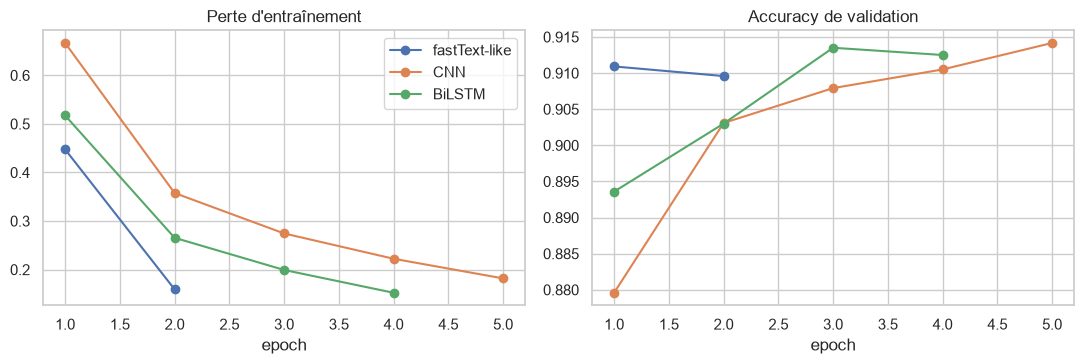

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for nom, h in historiques.items():
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], marker="o", label=nom)
    axes[1].plot(ep, h["val_acc"], marker="o", label=nom)
axes[0].set_title("Perte d'entraînement"); axes[0].set_xlabel("epoch")
axes[1].set_title("Accuracy de validation"); axes[1].set_xlabel("epoch")
axes[0].legend()
plt.tight_layout()
plt.show()

Les courbes montrent un comportement classique : la perte d'entraînement continue de baisser alors que l'accuracy de validation plafonne très vite, souvent dès la 2e ou 3e epoch. Au-delà, les réseaux commencent à surapprendre (ils mémorisent le train), d'où l'intérêt de l'early stopping.

## 6. Comparaison des modèles

In [27]:
res = pd.DataFrame(resultats).set_index("modèle")
res.sort_values("accuracy", ascending=False).style.format(
    {"accuracy": "{:.4f}", "f1_macro": "{:.4f}", "temps_entrainement_s": "{:.1f}", "nb_parametres": "{:,.0f}"}, na_rep="-")

,famille,accuracy,f1_macro,temps_entrainement_s,temps_prediction_test_s,nb_parametres
modèle,,,,,,
TF-IDF + SVM linéaire,ML classique,0.9221,0.9219,39.7,0.010000,-
TF-IDF + Régression logistique,ML classique,0.9212,0.9210,104.6,0.020000,-
CNN 1D,Deep learning,0.9097,0.9098,482.7,1.9,"5,915,012"
BiLSTM,Deep learning,0.9083,0.9082,704.1,2.690000,"5,981,700"
TF-IDF + Naive Bayes,ML classique,0.9068,0.9064,36.8,0.030000,-
Embeddings moyennés + bigrammes (fastText),Deep learning,0.9054,0.9053,366.7,0.070000,"34,858,500"
Baseline (classe majoritaire),baseline,0.2500,0.1000,0.0,0.0,-


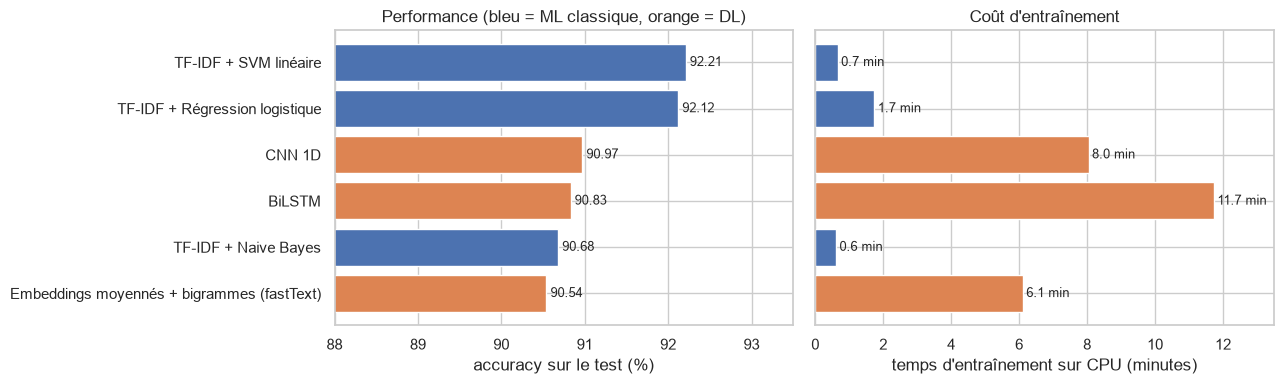

In [28]:
r = res.drop("Baseline (classe majoritaire)").sort_values("accuracy")
couleurs = ["#4C72B0" if f == "ML classique" else "#DD8452" for f in r.famille]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(r.index, r.accuracy * 100, color=couleurs)
axes[0].set_xlim(88, 93.5)
axes[0].set_xlabel("accuracy sur le test (%)")
for i, v in enumerate(r.accuracy * 100):
    axes[0].text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=9)
axes[0].set_title("Performance (bleu = ML classique, orange = DL)")

axes[1].barh(r.index, r.temps_entrainement_s / 60, color=couleurs)
axes[1].set_yticklabels([])
axes[1].set_xlabel("temps d'entraînement sur CPU (minutes)")
for i, v in enumerate(r.temps_entrainement_s / 60):
    axes[1].text(v + 0.1, i, f"{v:.1f} min", va="center", fontsize=9)
axes[1].set_xlim(0, 13.5)
axes[1].set_title("Coût d'entraînement")
plt.tight_layout()
plt.show()

### Ce qu'on peut en retenir

Plusieurs constats ressortent du tableau :

- **Tous les modèles font beaucoup mieux que la baseline** (25 %) et se situent entre 90,5 % et 92,2 % d'accuracy. Les écarts entre modèles sont donc assez faibles.
- **Les modèles linéaires sur TF-IDF sont les meilleurs** : le SVM linéaire (92,2 %) et la régression logistique (92,1 %) arrivent en tête, devant le CNN (91,0 %) et le BiLSTM (90,8 %). Le Naive Bayes est un peu en dessous (90,7 %), ce qui était attendu vu son hypothèse d'indépendance des mots.
- **Le deep learning n'apporte rien ici**, au contraire. Ça s'explique assez bien : les articles sont courts (~38 mots) et la catégorie dépend surtout de quelques mots-clés très discriminants (*match*, *shares*, *software*...). Un sac de mots avec bigrammes capture déjà l'essentiel. Les réseaux entraînés depuis zéro ont beaucoup de paramètres (~6 millions) et surapprennent vite, comme on l'a vu sur les courbes. On note quand même que le CNN progressait encore à la 5e epoch, il aurait peut-être gagné quelques dixièmes avec plus d'entraînement.
- **Le coût n'est pas du tout le même** : le SVM s'entraîne en ~40 s (dont la majorité pour le TF-IDF) et prédit les 7 600 articles du test en quelques millisecondes, contre 8 à 12 minutes d'entraînement sur CPU pour le CNN et le BiLSTM.

**Choix du modèle : TF-IDF + SVM linéaire.** C'est le meilleur modèle sur la validation (92,8 % contre 92,4 % pour la régression logistique), et c'est la validation qui doit servir à choisir le modèle, pas le test. Sur le test, l'écart avec la régression logistique est très faible (0,1 point, soit environ 7 articles), donc les deux restent des choix tout à fait défendables. En plus d'être le plus performant, le SVM est le plus rapide, léger à déployer (pas besoin de PyTorch sur le serveur) et interprétable.

## 7. Analyse du modèle retenu

### 7.1 Rapport de classification et matrice de confusion

              precision    recall  f1-score   support

       Monde      0.939     0.904     0.921      1900
       Sport      0.956     0.985     0.970      1900
    Business      0.897     0.892     0.894      1900
    Sci/Tech      0.897     0.907     0.902      1900

    accuracy                          0.922      7600
   macro avg      0.922     0.922     0.922      7600
weighted avg      0.922     0.922     0.922      7600



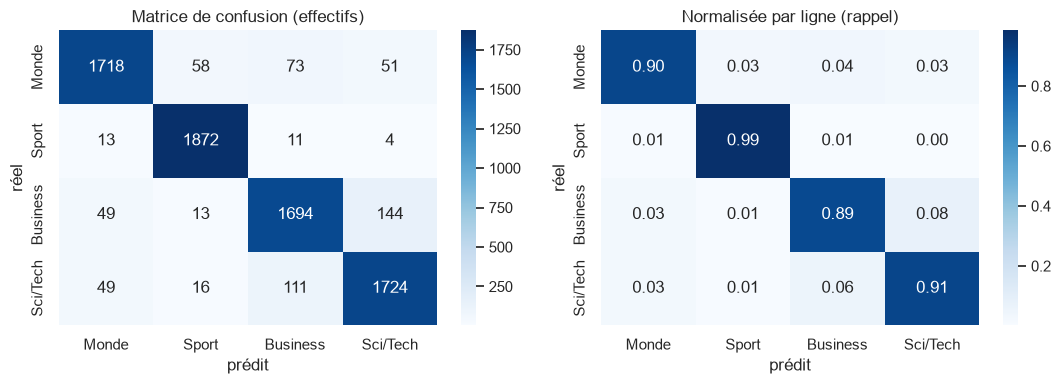

In [29]:
y_pred = svm.predict(A_test)
print(classification_report(y_test, y_pred, target_names=LABELS, digits=3))

cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
axes[0].set_title("Matrice de confusion (effectifs)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_title("Normalisée par ligne (rappel)")
for ax in axes:
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout()
plt.show()

Le modèle est très bon sur **Sport** (98,5 % de rappel) : le vocabulaire sportif est très spécifique. La classe la plus difficile est **Business** (F1 = 0,89).

La principale source d'erreurs est la confusion **Business ↔ Sci/Tech** : 144 articles Business classés Sci/Tech et 111 dans l'autre sens, soit environ 43 % de toutes les erreurs. C'est logique, car beaucoup d'articles parlent d'entreprises tech (Microsoft, IBM, Oracle, Google...) et peuvent relever des deux catégories. Vient ensuite Monde, confondu avec Business (sujets économiques et politiques, pétrole) et parfois avec Sport (événements internationaux comme les JO).

### 7.2 Mots les plus influents par classe
Un des avantages du modèle linéaire : on peut lire directement les poids. Voici les termes qui poussent le plus vers chaque classe.

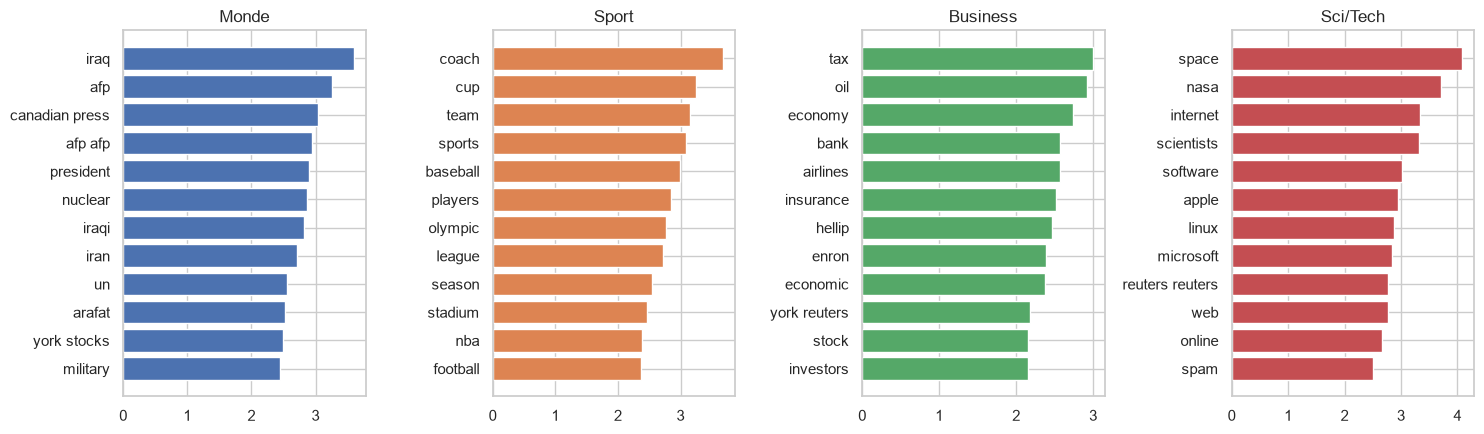

In [30]:
noms = np.array(tfidf.get_feature_names_out())
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for k, ax in enumerate(axes):
    top = np.argsort(svm.coef_[k])[-12:]
    ax.barh(noms[top], svm.coef_[k][top], color=sns.color_palette()[k])
    ax.set_title(LABELS[k])
plt.tight_layout()
plt.show()

### 7.3 Exemples d'erreurs

In [31]:
erreurs = test_df.assign(pred=y_pred)[y_pred != y_test]
for _, row in erreurs.sample(8, random_state=3).iterrows():
    print(f"[réel : {LABELS[row.label]:8s} | prédit : {LABELS[row.pred]:8s}] {row.text[:160]}")

[réel : Sci/Tech | prédit : Sport   ] Next gen games prove a challenge Making games for the future consoles is going to take a lot of time and money, a games conference is told.
[réel : Business | prédit : Sci/Tech] Judge asked to penalize Microsoft over e-mails Burst.com asked a US judge to penalize Microsoft for destroying e-mails it says the world #39;s largest software 
[réel : Sci/Tech | prédit : Sport   ] Meditation Practice Helping Arthritis Patients By ALEX DOMINGUEZ    BALTIMORE (AP) -- Dalia Isicoff knows pain. A lifelong sufferer of rheumatoid arthritis, she
[réel : Sport    | prédit : Sci/Tech] Ramirez should be taking it to heart When it comes down to this, when it's worse than you could have possibly imagined, if you are any kind of ballplayer at all
[réel : Sci/Tech | prédit : Business] Cingular to Cut About 7,000 Jobs (Reuters) Reuters - Cingular Wireless will cut about 7,000\jobs, or 10 percent of its work force, to cut costs as it\integrates
[réel : Business | prédit 

Beaucoup d'erreurs sont en fait discutables : un article sur les résultats financiers d'une entreprise tech peut aussi bien être classé Business que Sci/Tech, et un article sur la politique pétrolière d'un pays est à la fois Monde et Business. Une partie de ces erreurs vient donc de l'ambiguïté des catégories elles-mêmes plutôt que d'une faiblesse du modèle.

### 7.4 Obtenir des probabilités fiables

La webapp doit afficher la catégorie **avec sa probabilité**. Le `LinearSVC` ne renvoie qu'un score de distance à l'hyperplan, pas une probabilité. J'utilise donc `CalibratedClassifierCV` : il entraîne le SVM sur plusieurs plis et apprend une fonction (sigmoïde, méthode de Platt) qui transforme les scores en probabilités.

On compare la qualité des probabilités avec celles de la régression logistique à l'aide de la *log loss* (plus c'est bas, mieux c'est) et d'une courbe de fiabilité : si le modèle annonce 80 % de confiance, il devrait avoir raison environ 80 % du temps.

entraînement calibré : 15.4 s
SVM calibré            accuracy = 0.9207 | log loss = 0.2510
Régression logistique  accuracy = 0.9212 | log loss = 0.2485


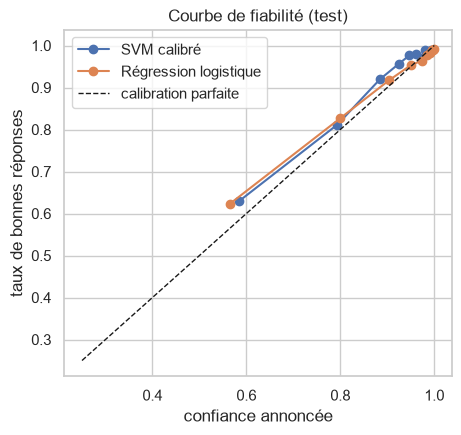

In [32]:
t0 = time.time()
svm_cal = CalibratedClassifierCV(LinearSVC(C=0.25), method="sigmoid", cv=5).fit(A_tr, y_tr)
print(f"entraînement calibré : {time.time() - t0:.1f} s")

proba_svm = svm_cal.predict_proba(A_test)
proba_lr = lr.predict_proba(A_test)
for nom, pr in [("SVM calibré", proba_svm), ("Régression logistique", proba_lr)]:
    print(f"{nom:22s} accuracy = {accuracy_score(y_test, pr.argmax(1)):.4f} | log loss = {log_loss(y_test, pr):.4f}")

plt.figure(figsize=(5, 4.5))
for nom, pr in [("SVM calibré", proba_svm), ("Régression logistique", proba_lr)]:
    conf = pr.max(1); juste = (pr.argmax(1) == y_test)
    fx, fy = calibration_curve(juste, conf, n_bins=10, strategy="quantile")
    plt.plot(fy, fx, marker="o", label=nom)
plt.plot([0.25, 1], [0.25, 1], "k--", lw=1, label="calibration parfaite")
plt.xlabel("confiance annoncée"); plt.ylabel("taux de bonnes réponses")
plt.title("Courbe de fiabilité (test)")
plt.legend()
plt.show()

Après calibration, le SVM garde quasiment la même accuracy et fournit des probabilités de bonne qualité : la log loss est proche de celle de la régression logistique (0,251 contre 0,249), et la courbe de fiabilité est proche de la diagonale. Les deux modèles sont même légèrement **sous-confiants** : la courbe est un peu au-dessus de la diagonale, donc quand le modèle annonce 60 %, il a en réalité raison environ 63 % du temps. Pour un utilisateur, c'est le défaut le moins gênant : la probabilité affichée est plutôt prudente.

La calibration ne change pas les performances de classification, mais elle rend la probabilité affichée dans la webapp interprétable, ce qui était demandé.

### 7.5 Modèle final et sauvegarde

Pour la version déployée, je réentraîne le pipeline complet (TF-IDF + SVM calibré) sur **l'ensemble du train** (train + validation), puisque les hyperparamètres sont maintenant fixés. Le pipeline est sauvegardé avec `joblib` dans le dossier de l'API Flask.

In [33]:
import joblib
import sklearn

modele_final = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=300_000)),
    ("clf", CalibratedClassifierCV(LinearSVC(C=0.25), method="sigmoid", cv=5)),
])
t0 = time.time()
modele_final.fit(train_df.clean.values, train_df.label.values)
print(f"entraînement final : {time.time() - t0:.0f} s")
print("accuracy test (pour info) :", round(accuracy_score(y_test, modele_final.predict(X_test)), 4))

out = Path("../api/model")
out.mkdir(parents=True, exist_ok=True)
joblib.dump({"pipeline": modele_final, "labels": LABELS, "sklearn_version": sklearn.__version__},
            out / "agnews_svm.joblib", compress=3)
print("taille du fichier :", round((out / "agnews_svm.joblib").stat().st_size / 1e6, 1), "Mo")

entraînement final : 33 s


accuracy test (pour info) : 0.9208


taille du fichier : 41.8 Mo


Petit test sur des phrases inventées, comme le ferait un utilisateur de l'application :

In [34]:
phrases = [
    "Real Madrid beat Barcelona 3-1 in a thrilling match on Sunday night.",
    "Apple unveils a new chip that doubles the battery life of its laptops.",
    "The central bank raised interest rates again to fight inflation.",
    "Peace talks between the two countries resumed in Geneva after weeks of fighting.",
]
proba = modele_final.predict_proba([nettoyer(p) for p in phrases])
for ph, pr in zip(phrases, proba):
    print(f"{LABELS[pr.argmax()]:9s} ({pr.max():.1%})  <- {ph}")

Sport     (97.6%)  <- Real Madrid beat Barcelona 3-1 in a thrilling match on Sunday night.
Sci/Tech  (92.6%)  <- Apple unveils a new chip that doubles the battery life of its laptops.
Business  (94.8%)  <- The central bank raised interest rates again to fight inflation.
Monde     (94.6%)  <- Peace talks between the two countries resumed in Geneva after weeks of fighting.


## 8. Conclusion

- Sur AG News, la meilleure approche est aussi la plus simple : **TF-IDF (mots + bigrammes) + SVM linéaire**, avec **92,2 % d'accuracy** sur le test officiel. La version calibrée utilisée dans l'application est à 92,1 %.
- Les modèles de deep learning entraînés depuis zéro (fastText, CNN, BiLSTM) obtiennent entre 90,5 % et 91 % pour un coût d'entraînement 10 à 20 fois plus élevé. Sur des textes courts et un vocabulaire aussi discriminant, ils n'apportent pas de gain.
- Les erreurs restantes viennent surtout de la frontière floue entre Business et Sci/Tech, qu'un humain aurait parfois du mal à trancher lui aussi.

**Limites :**
- les articles datent de 2004-2005 : un texte très récent peut contenir des mots inconnus du modèle (nouvelles entreprises, nouvelles technologies) ;
- le modèle ne fonctionne qu'en **anglais** ;
- il y a toujours exactement 4 classes : un texte hors sujet (une recette de cuisine par exemple) sera quand même rangé dans l'une d'elles.

**Pistes d'amélioration :** la piste la plus prometteuse serait un modèle **Transformer pré-entraîné** (BERT, DistilBERT, RoBERTa) affiné sur AG News. La littérature rapporte autour de 94-95 % d'accuracy, mais l'entraînement n'était pas réaliste sur ma machine sans GPU (plusieurs heures sur CPU). On pourrait aussi utiliser des embeddings pré-entraînés (GloVe) pour le CNN/LSTM, ou un ensemble combinant SVM et CNN.